# "SISTEM KLASIFIKASI KUALITAS TIDUR BERDASARKAN FAKTOR GAYA HIDUP DAN KONDISI KESEHATAN"

**Nama Kelompok:**
1. Jihaan Hanifah (4524210047)
2. Khoiril Chandra Kurniawan (4524210049)
3. M.AL GHIFARI (4524210052)
4. Nur Inayah Yusrizal (4524210117)
5. Maria Natalia Alyssa Beli (4524210133)

## 1. Import library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_columns", None)

## 2. Upload & baca dataset
Pilih file `Sleep_health_and_lifestyle_dataset.csv` saat tombol upload muncul.

In [ ]:
from google.colab import files
uploaded = files.upload()
FILE = list(uploaded.keys())[0]

df_raw = pd.read_csv(FILE)
print("Ukuran data:", df_raw.shape)
df_raw.head()

Saving Sleep_health_and_lifestyle_dataset.csv to Sleep_health_and_lifestyle_dataset.csv
Ukuran data: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 3. Cek data awal

In [ ]:
df_raw.info()
print()
print("Jumlah nilai kosong per kolom:")
print(df_raw.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB

Jumlah nilai kosong p

Kolom `Sleep Disorder` terbaca punya 219 nilai kosong. Itu bukan data hilang: tulisan `None` di CSV
(artinya **tidak ada gangguan tidur**) otomatis dibaca pandas sebagai kosong (NaN). Ini diperbaiki di tahap preprocessing.

## 4. Preprocessing

In [ ]:
df = df_raw.copy()

TARGET = "Sleep Disorder"

# 1) NaN pada target sebenarnya label "None" (tidak ada gangguan)
df[TARGET] = df[TARGET].fillna("None").astype(str)

# 2) Samakan penulisan kategori BMI
df["BMI Category"] = df["BMI Category"].replace({"Normal Weight": "Normal"})

# 3) Pecah tekanan darah "126/83" jadi dua kolom numerik
bp = df["Blood Pressure"].str.split("/", expand=True).astype(int)
df["Systolic"] = bp[0]
df["Diastolic"] = bp[1]

# 4) Buang kolom yang tidak dipakai
df = df.drop(columns=["Person ID", "Blood Pressure"])

NUMERIC_COLS = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
                "Stress Level", "Heart Rate", "Daily Steps", "Systolic", "Diastolic"]
CATEGORICAL_COLS = ["Gender", "Occupation", "BMI Category"]

print("Nilai kosong setelah preprocessing:", df.isnull().sum().sum())
print("Data duplikat:", df.duplicated().sum())
df.head()

Nilai kosong setelah preprocessing: 0
Data duplikat: 242


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic,Diastolic
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


## 5. Statistik deskriptif

In [ ]:
df[NUMERIC_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,374.0,42.184492,8.673133,27.0,35.25,43.0,50.0,59.0
Sleep Duration,374.0,7.132086,0.795657,5.8,6.40,7.2,7.8,8.5
Quality of Sleep,374.0,7.312834,1.196956,4.0,6.00,7.0,8.0,9.0
Physical Activity Level,374.0,59.171123,20.830804,30.0,45.00,60.0,75.0,90.0
Stress Level,374.0,5.385027,1.774526,3.0,4.00,5.0,7.0,8.0
Heart Rate,374.0,70.165775,4.135676,65.0,68.00,70.0,72.0,86.0
Daily Steps,374.0,6816.844920,1617.915679,3000.0,5600.00,7000.0,8000.0,10000.0
Systolic,374.0,128.553476,7.748118,115.0,125.00,130.0,135.0,142.0
Diastolic,374.0,84.649733,6.161611,75.0,80.00,85.0,90.0,95.0


In [ ]:
# Ukuran pemusatan & penyebaran tambahan
ringkas = pd.DataFrame({
    "Mean": df[NUMERIC_COLS].mean(),
    "Median": df[NUMERIC_COLS].median(),
    "Modus": df[NUMERIC_COLS].mode().iloc[0],
    "Std Dev": df[NUMERIC_COLS].std(),
    "Variansi": df[NUMERIC_COLS].var(),
    "Skewness": df[NUMERIC_COLS].skew(),
}).round(3)
ringkas

,Mean,Median,Modus,Std Dev,Variansi,Skewness
Age,42.184,43.0,43.0,8.673,75.223,0.257
Sleep Duration,7.132,7.2,7.2,0.796,0.633,0.038
Quality of Sleep,7.313,7.0,8.0,1.197,1.433,-0.207
Physical Activity Level,59.171,60.0,60.0,20.831,433.922,0.074
Stress Level,5.385,5.0,3.0,1.775,3.149,0.154
Heart Rate,70.166,70.0,68.0,4.136,17.104,1.225
Daily Steps,6816.845,7000.0,8000.0,1617.916,2617651.145,0.178
Systolic,128.553,130.0,130.0,7.748,60.033,-0.036
Diastolic,84.650,85.0,80.0,6.162,37.965,0.379


## 6. Visualisasi distribusi

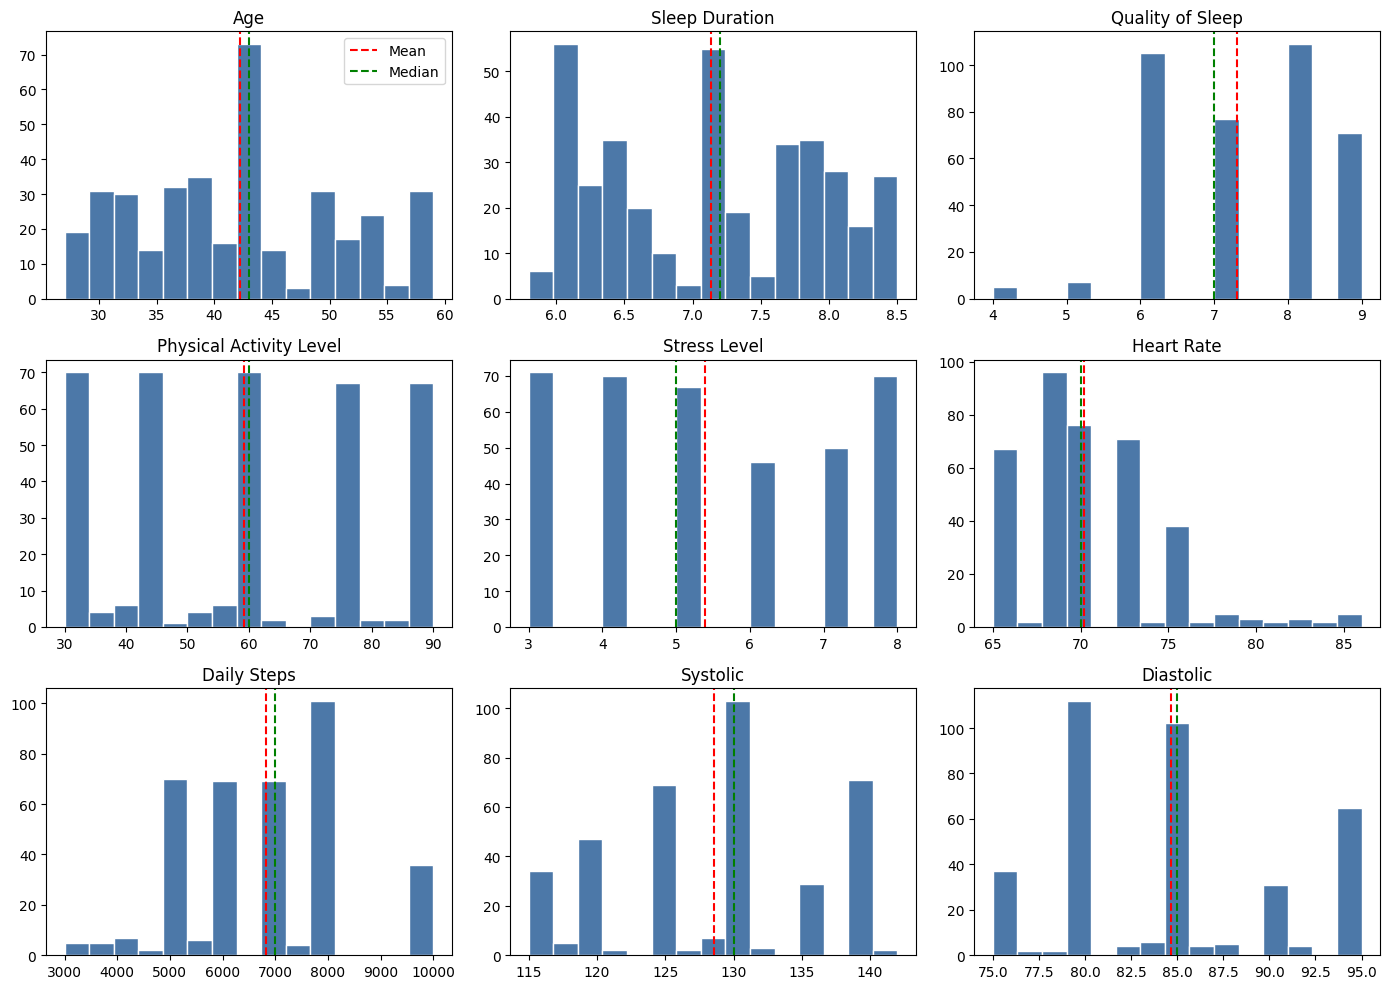

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    ax.hist(df[col], bins=15, color="#4C78A8", edgecolor="white")
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="Mean")
    ax.axvline(df[col].median(), color="green", linestyle="--", label="Median")
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

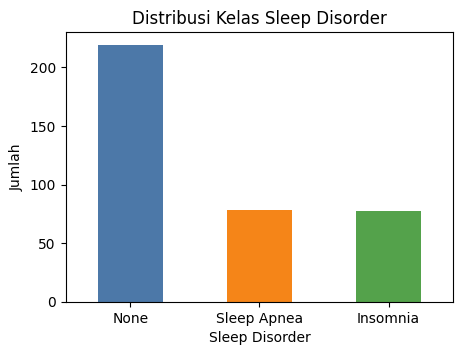

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.5))
df[TARGET].value_counts().plot(kind="bar", color=["#4C78A8", "#F58518", "#54A24B"], ax=ax)
ax.set_title("Distribusi Kelas Sleep Disorder")
ax.set_ylabel("Jumlah")
plt.xticks(rotation=0)
plt.show()

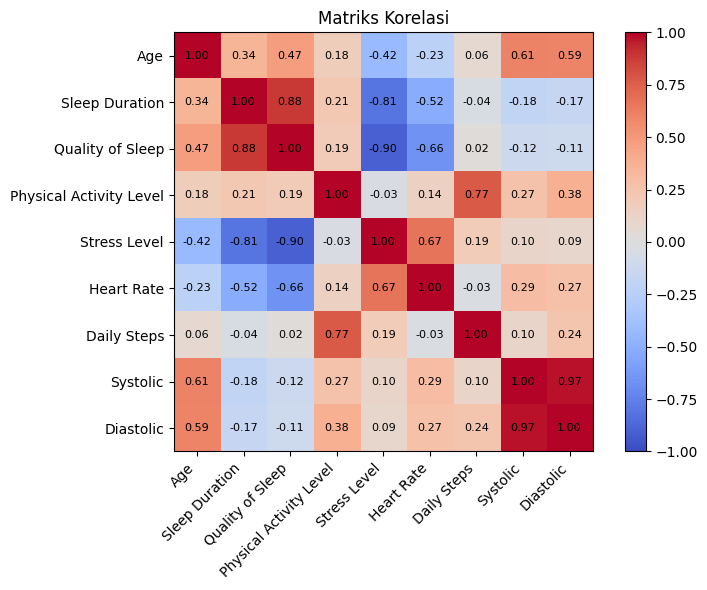

In [ ]:
# Korelasi antar variabel numerik
corr = df[NUMERIC_COLS].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
ax.set_title("Matriks Korelasi")
plt.tight_layout()
plt.show()

## 7. Probabilitas

In [ ]:
# Probabilitas marginal tiap kelas: P(kelas)
prior = df[TARGET].value_counts(normalize=True).round(3)
print("P(Sleep Disorder):")
print(prior)

P(Sleep Disorder):
Sleep Disorder
None           0.586
Sleep Apnea    0.209
Insomnia       0.206
Name: proportion, dtype: float64


In [ ]:
# Probabilitas bersyarat: P(Sleep Disorder | BMI Category)
print("P(Sleep Disorder | BMI Category):")
display(pd.crosstab(df["BMI Category"], df[TARGET], normalize="index").round(3))

print("P(Sleep Disorder | Occupation):")
display(pd.crosstab(df["Occupation"], df[TARGET], normalize="index").round(3))

print("P(Sleep Disorder | Gender):")
display(pd.crosstab(df["Gender"], df[TARGET], normalize="index").round(3))

P(Sleep Disorder | BMI Category):


Sleep Disorder,Insomnia,None,Sleep Apnea
BMI Category,,,
Normal,0.042,0.926,0.032
Obese,0.400,0.000,0.600
Overweight,0.432,0.128,0.439


P(Sleep Disorder | Occupation):


Sleep Disorder,Insomnia,None,Sleep Apnea
Occupation,,,
Accountant,0.189,0.811,0.000
Doctor,0.042,0.901,0.056
Engineer,0.079,0.905,0.016
Lawyer,0.043,0.894,0.064
Manager,0.000,1.000,0.000
Nurse,0.041,0.123,0.836
Sales Representative,0.000,0.000,1.000
Salesperson,0.906,0.062,0.031
Scientist,0.000,0.500,0.500


P(Sleep Disorder | Gender):


Sleep Disorder,Insomnia,None,Sleep Apnea
Gender,,,
Female,0.195,0.443,0.362
Male,0.217,0.725,0.058


In [ ]:
# Contoh hitung manual dengan Teorema Bayes:
# P(Sleep Apnea | Overweight) = P(Overweight | Sleep Apnea) * P(Sleep Apnea) / P(Overweight)
p_apnea = (df[TARGET] == "Sleep Apnea").mean()
p_over = (df["BMI Category"] == "Overweight").mean()
p_over_given_apnea = (df.loc[df[TARGET] == "Sleep Apnea", "BMI Category"] == "Overweight").mean()

bayes = p_over_given_apnea * p_apnea / p_over
langsung = (df.loc[df["BMI Category"] == "Overweight", TARGET] == "Sleep Apnea").mean()

print(f"P(Sleep Apnea)              = {p_apnea:.3f}")
print(f"P(Overweight)               = {p_over:.3f}")
print(f"P(Overweight | Sleep Apnea) = {p_over_given_apnea:.3f}")
print(f"P(Sleep Apnea | Overweight) via Bayes     = {bayes:.3f}")
print(f"P(Sleep Apnea | Overweight) hitung langsung = {langsung:.3f}")

P(Sleep Apnea)              = 0.209
P(Overweight)               = 0.396
P(Overweight | Sleep Apnea) = 0.833
P(Sleep Apnea | Overweight) via Bayes     = 0.439
P(Sleep Apnea | Overweight) hitung langsung = 0.439


## 8. Split data & membangun model

In [ ]:
X = df[NUMERIC_COLS + CATEGORICAL_COLS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

def make_pipeline(model):
    prep = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
    ])
    return Pipeline([("prep", prep), ("model", model)])

models = {
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
}

Data latih: (299, 12) | Data uji: (75, 12)


## 9. Training & perbandingan model

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fitted, hasil = {}, []

for nama, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv_acc = cross_val_score(make_pipeline(model), X, y, cv=cv)
    hasil.append({
        "Model": nama,
        "Akurasi (data uji)": accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "Akurasi CV 5-fold": cv_acc.mean(),
    })
    fitted[nama] = pipe

hasil_df = pd.DataFrame(hasil).sort_values("Akurasi (data uji)", ascending=False).round(3).reset_index(drop=True)
hasil_df

,Model,Akurasi (data uji),F1 macro,Akurasi CV 5-fold
0,Logistic Regression,0.947,0.920,0.909
1,K-Nearest Neighbors,0.947,0.928,0.893
2,Decision Tree,0.933,0.901,0.896
3,Naive Bayes (Gaussian),0.893,0.877,0.877


## 10. Evaluasi model terbaik

Model terbaik: Logistic Regression

              precision    recall  f1-score   support

    Insomnia       0.92      0.80      0.86        15
        None       1.00      0.98      0.99        44
 Sleep Apnea       0.84      1.00      0.91        16

    accuracy                           0.95        75
   macro avg       0.92      0.93      0.92        75
weighted avg       0.95      0.95      0.95        75



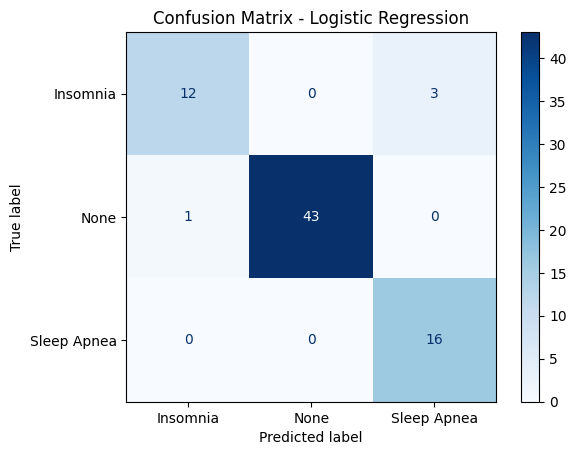

In [ ]:
best_name = hasil_df.loc[0, "Model"]
best = fitted[best_name]
pred = best.predict(X_test)
labels = sorted(y.unique())
print("Model terbaik:", best_name)
print()
print(classification_report(y_test, pred, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

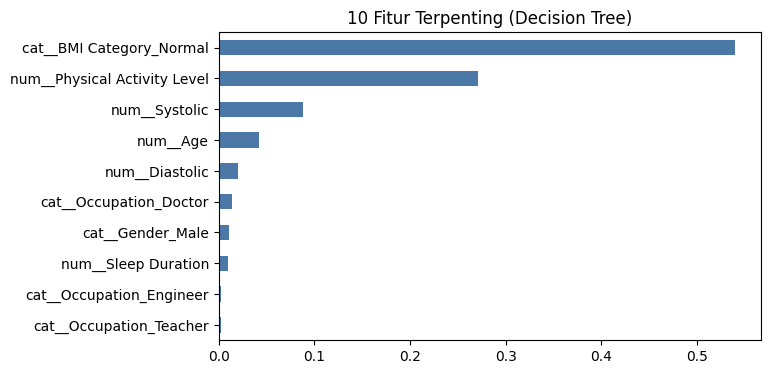

In [ ]:
# Fitur paling berpengaruh menurut Decision Tree
tree = fitted["Decision Tree"]
nama_fitur = tree.named_steps["prep"].get_feature_names_out()
imp = pd.Series(tree.named_steps["model"].feature_importances_, index=nama_fitur).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", figsize=(7, 4), color="#4C78A8")
plt.title("10 Fitur Terpenting (Decision Tree)")
plt.show()

## 11. (Opsional) Simpan data bersih

In [ ]:
df.to_csv("sleep_cleaned.csv", index=False)
files.download("sleep_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>